# Manufacturing Downtime – Exploratory Data Analysis

Exploration of the clean star schema tables (`data/clean`) to understand where and why the soda line loses time.

**Sections**
1. Load the data
2. Overall picture
3. Downtime causes (Pareto)
4. Human vs machine vs material
5. Operators
6. Products
7. Days and shifts
8. Worst batches
9. Summary

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("../data/clean")
FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3})
COLOR = "#1f4e79"
ACCENT = "#c0504d"

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", dpi=150)

## 1. Load the data

In [2]:
product   = pd.read_csv(DATA / "Dim_Product.csv")
operator  = pd.read_csv(DATA / "Dim_Operator.csv")
factor    = pd.read_csv(DATA / "Dim_DowntimeFactor.csv")
date      = pd.read_csv(DATA / "Dim_Date.csv", parse_dates=["Date"])
batch     = pd.read_csv(DATA / "Fact_Batch.csv")
downtime  = pd.read_csv(DATA / "Fact_Downtime.csv")

# One wide table per grain, joined through the star schema keys
batches = (batch.merge(product, on="ProductID")
                .merge(operator, on="OperatorID")
                .merge(date, on="DateKey"))
events = (downtime.merge(factor, on="FactorID")
                  .merge(batches[["BatchID", "ProductID", "Operator_Name", "Shift", "Date"]],
                         on="BatchID"))

for name, df in {"Dim_Product": product, "Dim_Operator": operator,
                 "Dim_DowntimeFactor": factor, "Dim_Date": date,
                 "Fact_Batch": batch, "Fact_Downtime": downtime}.items():
    print(f"{name:<20} {df.shape[0]:>3} rows  {df.shape[1]} columns")

Dim_Product            6 rows  5 columns
Dim_Operator           4 rows  3 columns
Dim_DowntimeFactor    12 rows  4 columns
Dim_Date               6 rows  6 columns
Fact_Batch            38 rows  9 columns
Fact_Downtime         61 rows  4 columns


## 2. Overall picture

In [3]:
production = batches["Batch_Duration_Min"].sum()
lost = batches["Total_Downtime_Min"].sum()
ideal = batches["Min_Batch_Time"].sum()

overview = pd.Series({
    "Batches": len(batches),
    "Days": batches["Date"].nunique(),
    "Production minutes": production,
    "Ideal minutes (min batch time)": ideal,
    "Downtime minutes": lost,
    "Downtime % of production": round(100 * lost / production, 1),
    "Overall efficiency %": round(100 * ideal / production, 1),
    "Batches with no downtime": int((batches["Total_Downtime_Min"] == 0).sum()),
})
overview

Batches                             38.0
Days                                 5.0
Production minutes                3858.0
Ideal minutes (min batch time)    2470.0
Downtime minutes                  1388.0
Downtime % of production            36.0
Overall efficiency %                64.0
Batches with no downtime             3.0
dtype: float64

In [4]:
# Check: every production minute is either ideal batch time or downtime
assert production == ideal + lost

## 3. Downtime causes (Pareto)

In [5]:
pareto = (events.groupby("Description")["Downtime_Minutes"].sum()
                .sort_values(ascending=False).to_frame("Minutes"))
pareto["Share %"] = (100 * pareto["Minutes"] / pareto["Minutes"].sum()).round(1)
pareto["Cumulative %"] = pareto["Share %"].cumsum().round(1)
pareto

,Minutes,Share %,Cumulative %
Description,,,
Machine adjustment,332,23.9,23.9
Machine failure,254,18.3,42.2
Inventory shortage,225,16.2,58.4
Batch change,160,11.5,69.9
Batch coding error,145,10.4,80.3
Other,74,5.3,85.6
Product spill,57,4.1,89.7
Calibration error,49,3.5,93.2
Labeling error,42,3.0,96.2


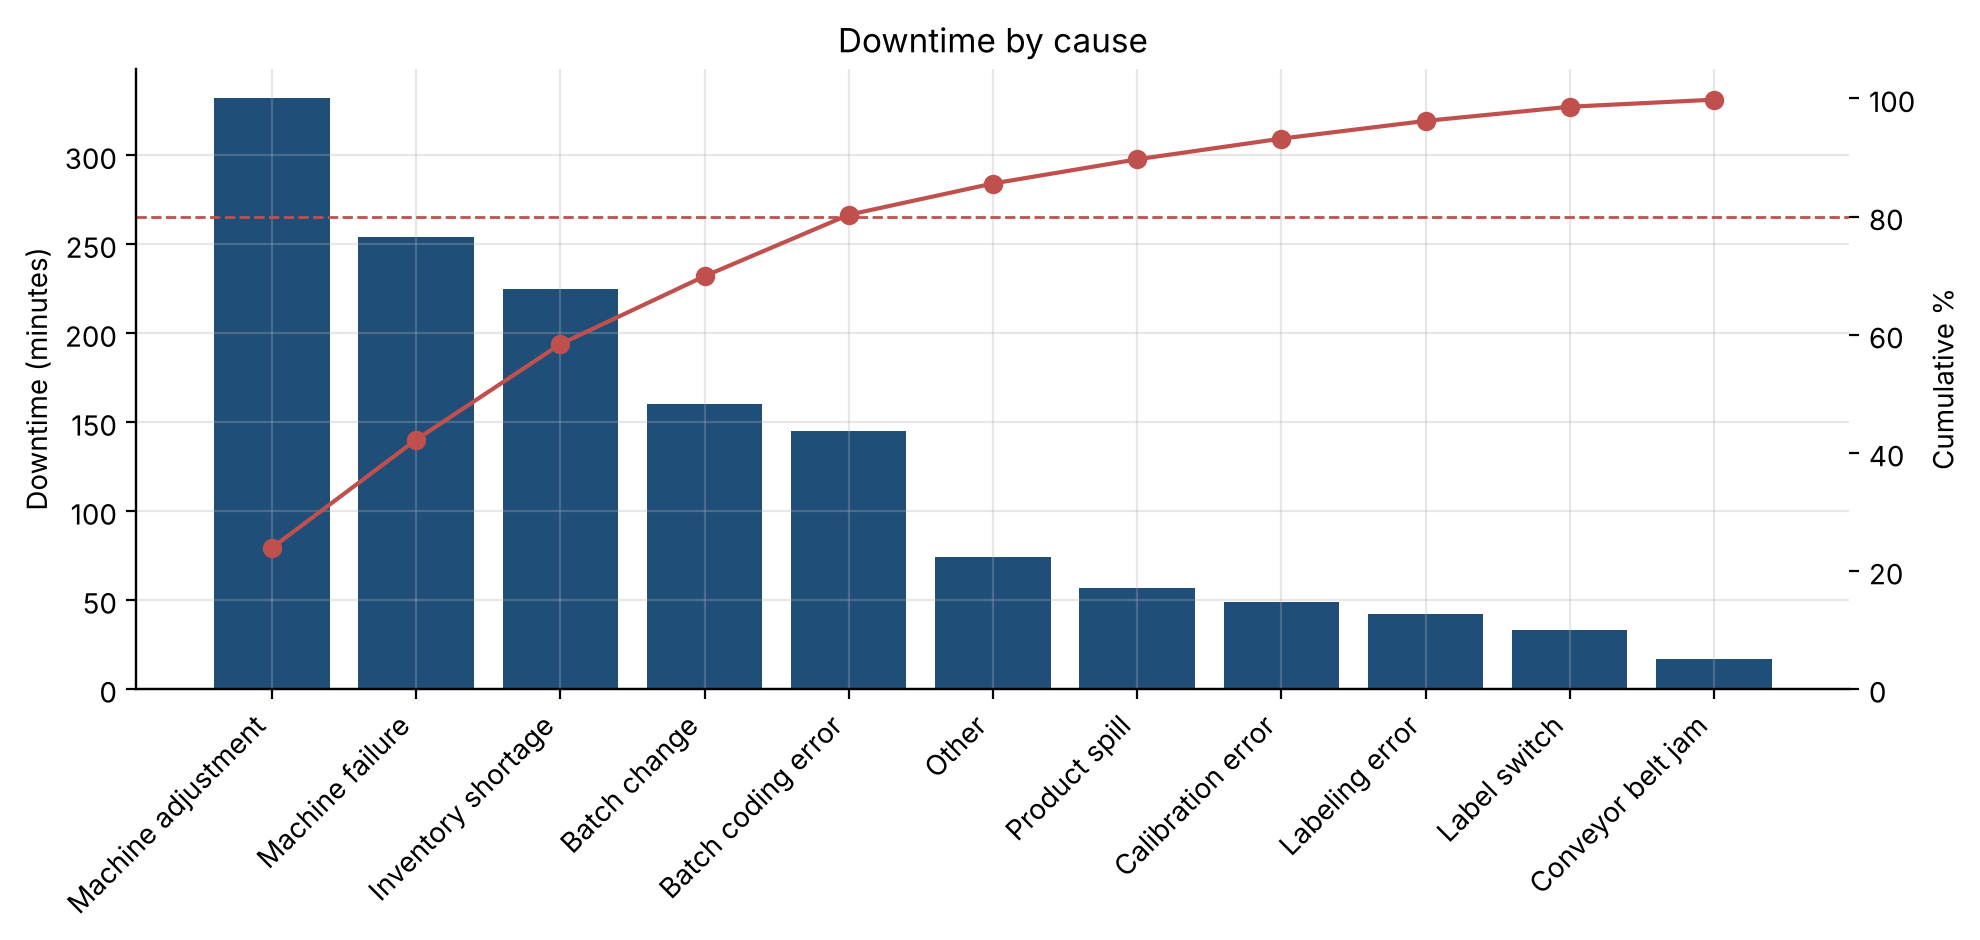

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(pareto.index, pareto["Minutes"], color=COLOR)
ax.set_ylabel("Downtime (minutes)")
ax.set_title("Downtime by cause")
ax.tick_params(axis="x", rotation=45)
for label in ax.get_xticklabels():
    label.set_ha("right")
ax2 = ax.twinx()
ax2.plot(pareto.index, pareto["Cumulative %"], color=ACCENT, marker="o")
ax2.axhline(80, color=ACCENT, linestyle="--", linewidth=1)
ax2.set_ylim(0, 105)
ax2.set_ylabel("Cumulative %")
ax2.grid(False)
save(fig, "01_downtime_pareto")
plt.show()

## 4. Human vs machine vs material

In [7]:
by_category = (events.groupby("Factor_Category")["Downtime_Minutes"].sum()
                      .sort_values(ascending=False))
by_category_pct = (100 * by_category / by_category.sum()).round(1)
pd.DataFrame({"Minutes": by_category, "Share %": by_category_pct})

,Minutes,Share %
Factor_Category,,
Human,776,55.9
Machine,313,22.6
Material,225,16.2
Other,74,5.3


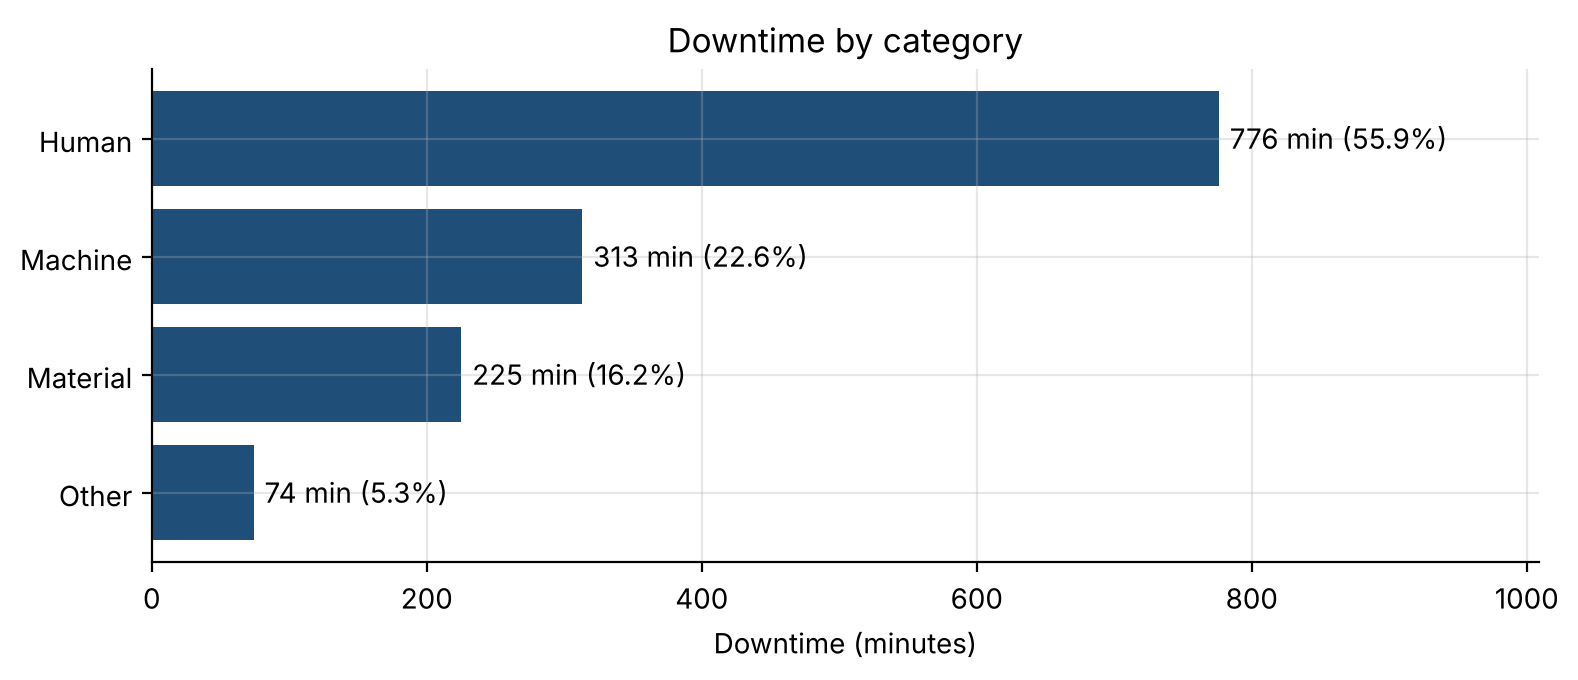

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(by_category.index[::-1], by_category.values[::-1], color=COLOR)
for i, v in enumerate(by_category.values[::-1]):
    ax.text(v + 8, i, f"{v} min ({by_category_pct.values[::-1][i]}%)", va="center")
ax.set_xlabel("Downtime (minutes)")
ax.set_title("Downtime by category")
ax.set_xlim(0, by_category.max() * 1.3)
save(fig, "02_downtime_by_category")
plt.show()

## 5. Operators

In [9]:
ops = batches.groupby(["Operator_Name", "Shift"]).agg(
    Batches=("BatchID", "count"),
    Production_Min=("Batch_Duration_Min", "sum"),
    Ideal_Min=("Min_Batch_Time", "sum"),
    Downtime_Min=("Total_Downtime_Min", "sum"),
).reset_index()
ops["Avg_Downtime_per_Batch"] = (ops["Downtime_Min"] / ops["Batches"]).round(1)
ops["Efficiency %"] = (100 * ops["Ideal_Min"] / ops["Production_Min"]).round(1)
ops.sort_values("Efficiency %", ascending=False)

,Operator_Name,Shift,Batches,Production_Min,Ideal_Min,Downtime_Min,Avg_Downtime_per_Batch,Efficiency %
0,Charlie,Evening,11,1158,774,384,34.9,66.8
1,Dee,Morning,11,1030,660,370,33.6,64.1
2,Dennis,Morning,8,820,518,302,37.8,63.2
3,Mac,Evening,8,850,518,332,41.5,60.9


In [10]:
human = (events[events["Operator_Error"] == "Yes"]
         .pivot_table(index="Operator_Name", columns="Description",
                      values="Downtime_Minutes", aggfunc="sum", fill_value=0))
human

Description,Batch change,Batch coding error,Calibration error,Label switch,Machine adjustment,Product spill
Operator_Name,,,,,,
Charlie,10,44,24,10,118,22
Dee,20,30,25,23,79,15
Dennis,0,24,0,0,120,20
Mac,130,47,0,0,15,0


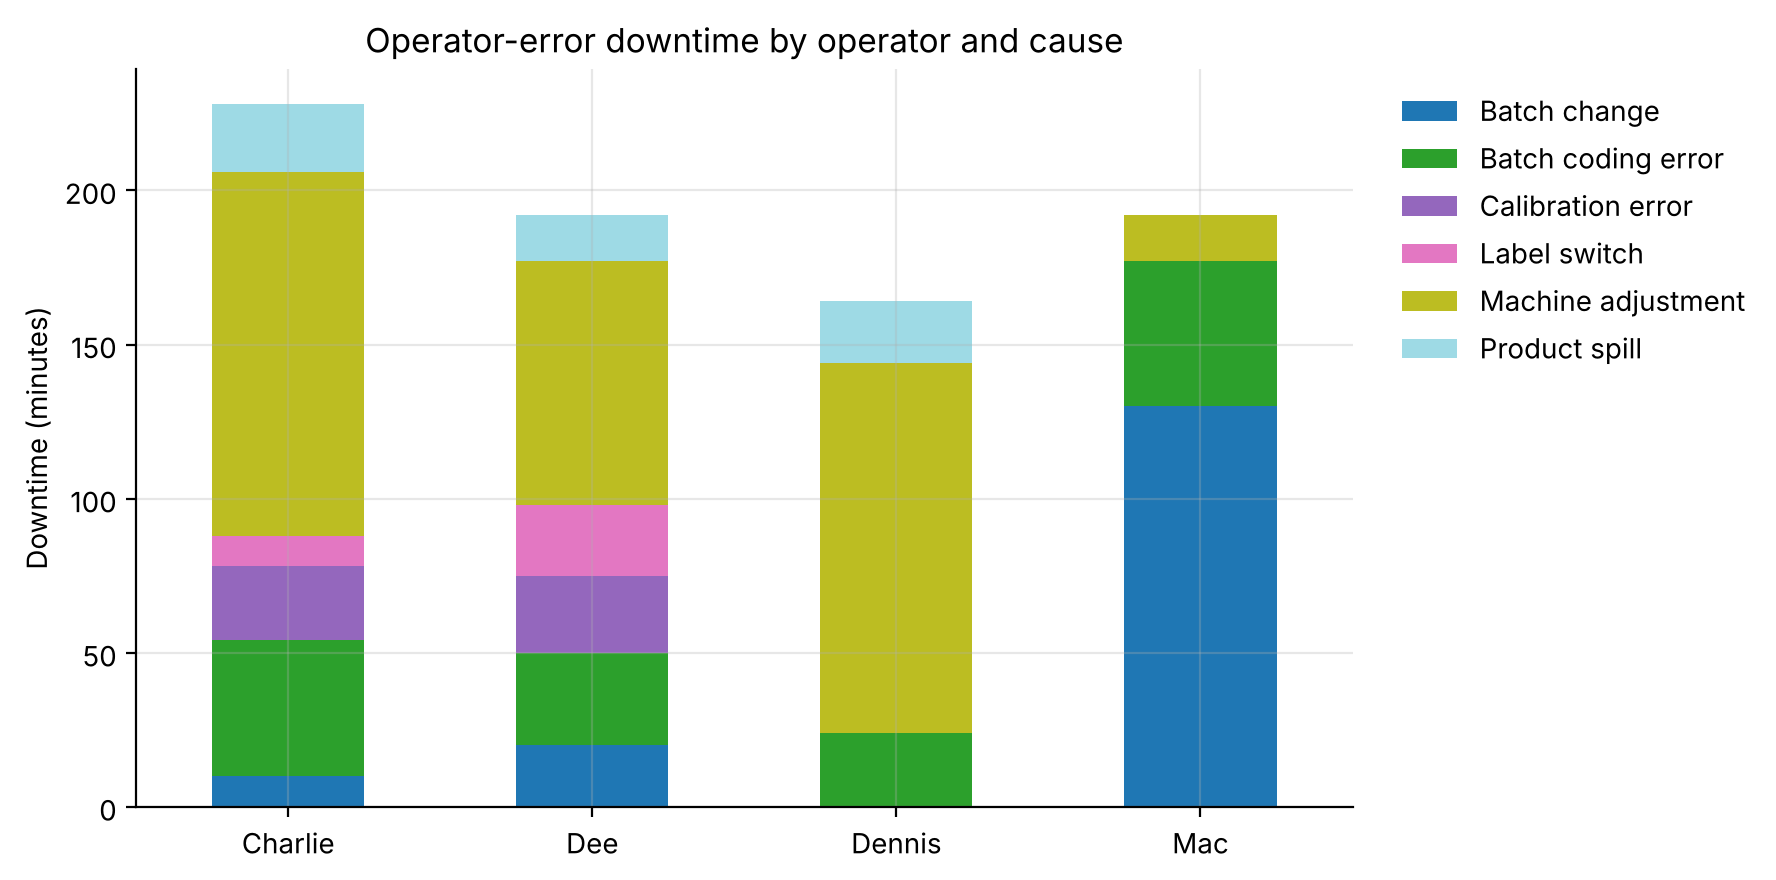

In [11]:
fig, ax = plt.subplots()
human.plot(kind="bar", stacked=True, ax=ax, colormap="tab20")
ax.set_ylabel("Downtime (minutes)")
ax.set_xlabel("")
ax.set_title("Operator-error downtime by operator and cause")
ax.tick_params(axis="x", rotation=0)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
save(fig, "03_operator_errors")
plt.show()

## 6. Products

In [12]:
prod = batches.groupby(["ProductID", "Flavor", "Size"]).agg(
    Batches=("BatchID", "count"),
    Production_Min=("Batch_Duration_Min", "sum"),
    Ideal_Min=("Min_Batch_Time", "sum"),
    Downtime_Min=("Total_Downtime_Min", "sum"),
).reset_index()
prod["Efficiency %"] = (100 * prod["Ideal_Min"] / prod["Production_Min"]).round(1)
prod = prod.sort_values("Efficiency %")
prod

,ProductID,Flavor,Size,Batches,Production_Min,Ideal_Min,Downtime_Min,Efficiency %
4,OR-600,Orange,600 ml,1,135,60,75,44.4
5,RB-600,Root Beer,600 ml,7,678,420,258,61.9
0,CO-2L,Cola,2 L,5,767,490,277,63.9
1,CO-600,Cola,600 ml,15,1394,900,494,64.6
2,DC-600,Diet Cola,600 ml,4,355,240,115,67.6
3,LE-600,Lemon Lime,600 ml,6,529,360,169,68.1


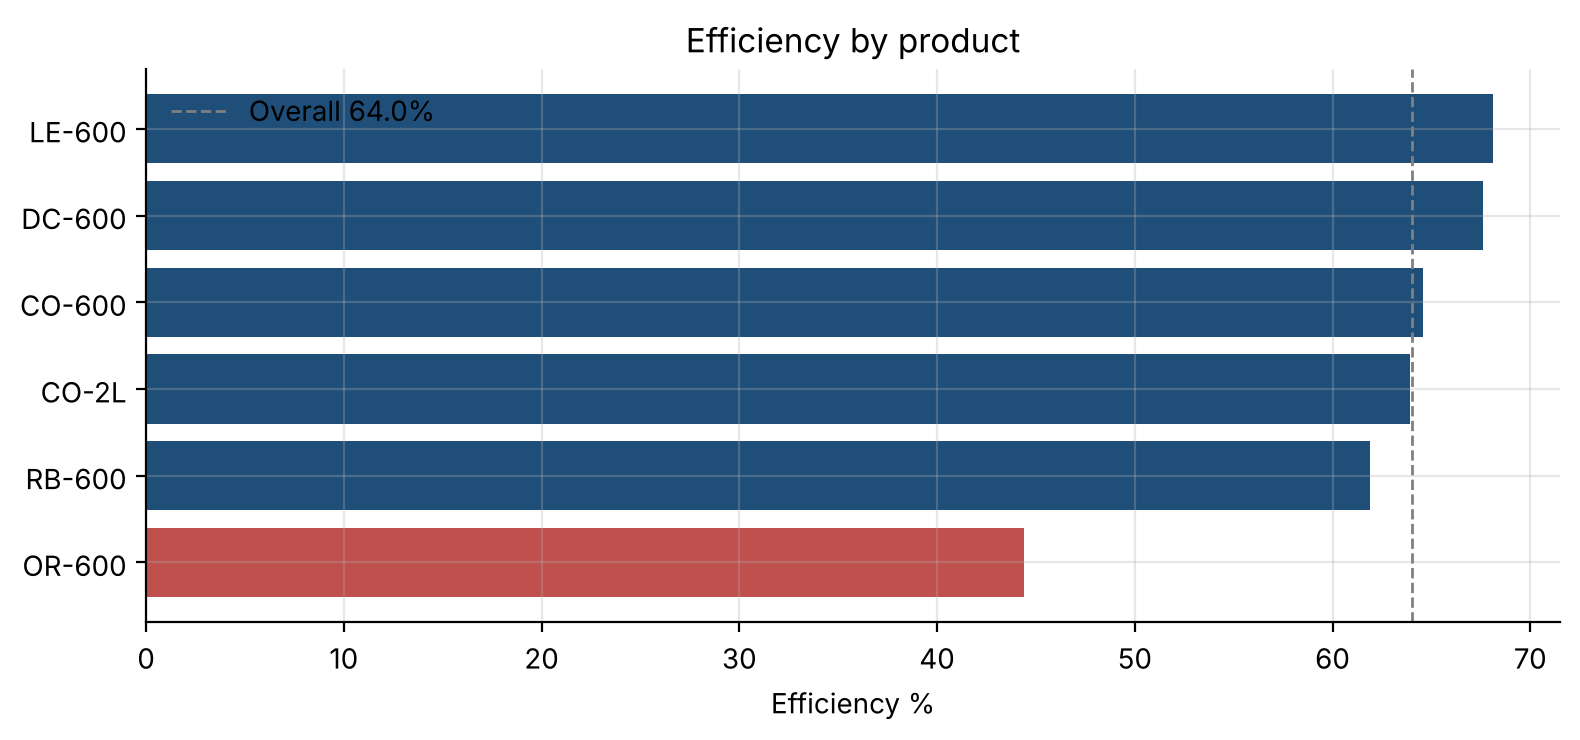

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.8))
colors = [ACCENT if v == prod["Efficiency %"].min() else COLOR for v in prod["Efficiency %"]]
ax.barh(prod["ProductID"], prod["Efficiency %"], color=colors)
ax.axvline(overview["Overall efficiency %"], color="grey", linestyle="--", linewidth=1,
           label=f"Overall {overview['Overall efficiency %']}%")
ax.set_xlabel("Efficiency %")
ax.set_title("Efficiency by product")
ax.legend(frameon=False)
save(fig, "04_product_efficiency")
plt.show()

## 7. Days and shifts

In [14]:
daily = batches.groupby("Date").agg(
    Batches=("BatchID", "count"),
    Production_Min=("Batch_Duration_Min", "sum"),
    Downtime_Min=("Total_Downtime_Min", "sum"),
)
daily["Downtime %"] = (100 * daily["Downtime_Min"] / daily["Production_Min"]).round(1)
daily

,Batches,Production_Min,Downtime_Min,Downtime %
Date,,,,
2024-08-29,7,664,244,36.7
2024-08-30,12,1164,444,38.1
2024-08-31,7,585,165,28.2
2024-09-02,11,1315,503,38.3
2024-09-03,1,130,32,24.6


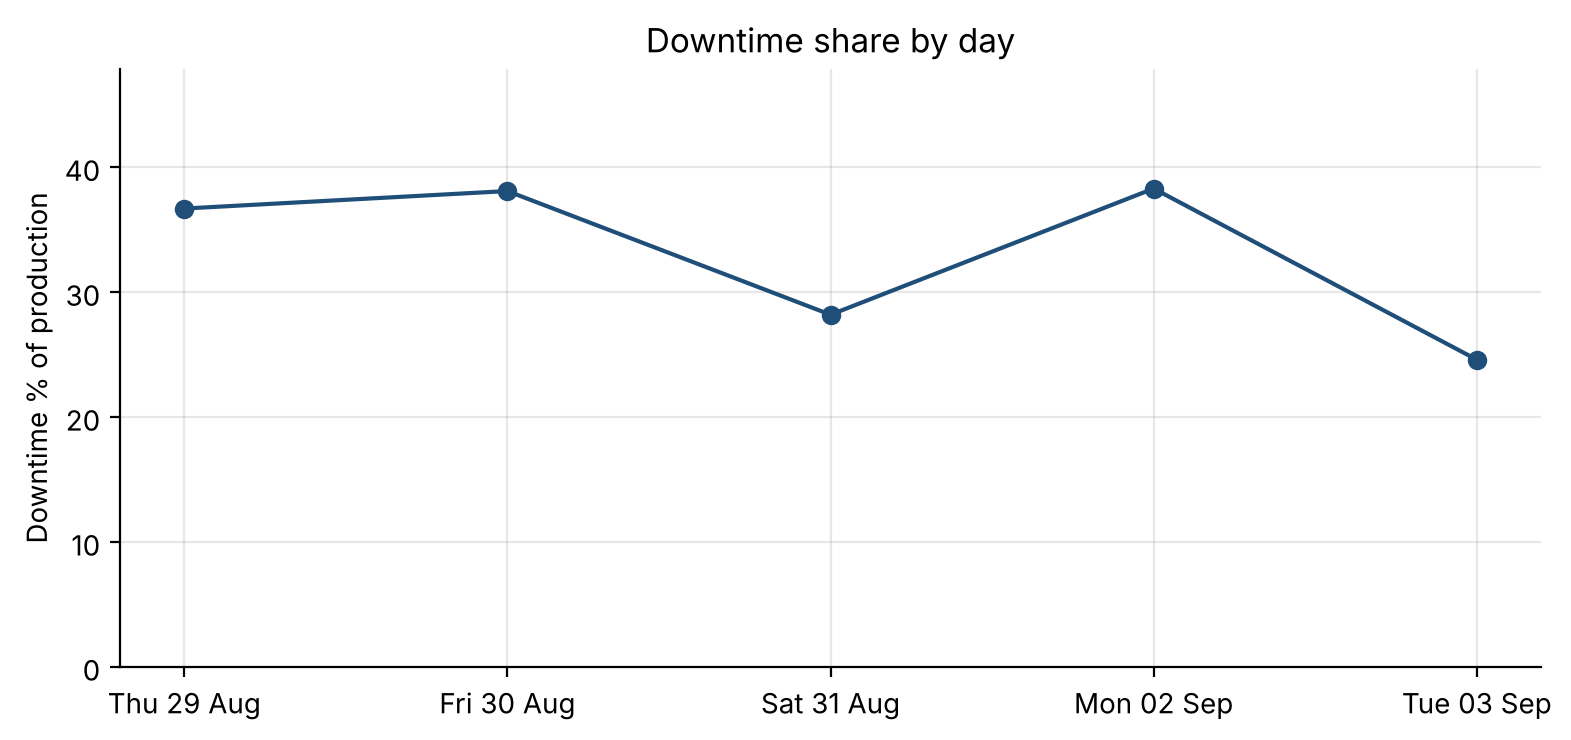

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(daily.index.strftime("%a %d %b"), daily["Downtime %"], marker="o", color=COLOR)
ax.set_ylabel("Downtime % of production")
ax.set_title("Downtime share by day")
ax.set_ylim(0, daily["Downtime %"].max() * 1.25)
save(fig, "05_daily_downtime")
plt.show()

In [16]:
shift = batches.groupby("Shift").agg(
    Batches=("BatchID", "count"),
    Avg_Downtime_per_Batch=("Total_Downtime_Min", "mean"),
).round(1)
shift

,Batches,Avg_Downtime_per_Batch
Shift,,
Evening,19,37.7
Morning,19,35.4


## 8. Worst batches

In [17]:
causes = (events.sort_values("Downtime_Minutes", ascending=False)
                .groupby("BatchID")
                .apply(lambda g: ", ".join(f"{d} ({m})" for d, m in
                                          zip(g["Description"], g["Downtime_Minutes"])),
                       include_groups=False)
                .rename("Causes"))
(batches.set_index("BatchID")[["ProductID", "Operator_Name", "Batch_Duration_Min",
                               "Total_Downtime_Min"]]
        .join(causes)
        .sort_values("Total_Downtime_Min", ascending=False)
        .head(5))

,ProductID,Operator_Name,Batch_Duration_Min,Total_Downtime_Min,Causes
BatchID,,,,,
422147,CO-2L,Charlie,205,107,"Machine adjustment (60), Machine failure (30),..."
422111,OR-600,Mac,135,75,"Batch change (60), Machine failure (15)"
422123,CO-600,Dennis,133,73,"Inventory shortage (43), Machine failure (30)"
422140,RB-600,Dee,123,63,"Machine adjustment (50), Label switch (13)"
422146,CO-2L,Charlie,160,62,"Machine adjustment (30), Machine failure (25),..."


## 9. Summary

In [18]:
top3 = pareto.head(3)
print(f"Downtime is {overview['Downtime % of production']}% of production time "
      f"({lost} of {production} minutes).")
print(f"Top 3 causes ({', '.join(top3.index)}) = {top3['Share %'].sum():.1f}% of downtime.")
print(f"Operator error (Human) = {by_category_pct.get('Human', 0)}% of downtime.")
best, worst = ops.loc[ops['Efficiency %'].idxmax()], ops.loc[ops['Efficiency %'].idxmin()]
print(f"Most efficient operator: {best['Operator_Name']} ({best['Efficiency %']}%), "
      f"least: {worst['Operator_Name']} ({worst['Efficiency %']}%).")
print(f"Least efficient product: {prod.iloc[0]['ProductID']} ({prod.iloc[0]['Efficiency %']}%).")

Downtime is 36.0% of production time (1388 of 3858 minutes).
Top 3 causes (Machine adjustment, Machine failure, Inventory shortage) = 58.4% of downtime.
Operator error (Human) = 55.9% of downtime.
Most efficient operator: Charlie (66.8%), least: Mac (60.9%).
Least efficient product: OR-600 (44.4%).
